# Máquinas de Vectores de Soporte (SVM)
### Regresión con SVR y clasificación con SVC

**Objetivo:** aplicar SVM a dos problemas distintos, comparar kernels, ajustar hiperparámetros y evaluar el desempeño con métricas apropiadas para cada tarea.

| Parte | Tarea | Dataset | Modelo | Métricas |
|---|---|---|---|---|
| 1 | Regresión | California Housing (20.640 × 8) | `SVR` | MAE, MSE, RMSE, R² |
| 2 | Clasificación | Breast Cancer Wisconsin (569 × 30) | `SVC` | Accuracy, Precision, Recall, F1, AUC |
| 3 | Comparación | — | — | Base vs. ajustado, train vs. test |

## Objetivo y motivación de la metodología

### Qué queremos lograr

El objetivo de este trabajo es aplicar **Máquinas de Vectores de Soporte (SVM)** a dos problemas de naturaleza distinta, una **regresión** y una **clasificación**, para mostrar que ambos casos se resuelven con el mismo principio matemático y para identificar qué decisiones prácticas determinan que el modelo funcione o no.

Una SVM no busca una frontera cualquiera entre los datos: busca la que deja **el mayor margen posible** entre las clases. En regresión, la misma idea se traduce en encontrar la función más plana que mantenga la mayoría de las observaciones dentro de un margen de tolerancia. Esta característica es la que diferencia a las SVM de otros métodos y la que queremos ver en funcionamiento sobre datos reales.

### Por qué dos conjuntos de datos y no uno

Los dos datasets se eligieron de forma deliberada porque tienen características **opuestas**. Esto permite demostrar que en SVM no existe una configuración que funcione siempre.

| | California Housing | Breast Cancer Wisconsin |
|---|---|---|
| **Tarea** | Regresión (`SVR`) | Clasificación binaria (`SVC`) |
| **Dimensiones** | 20.640 filas × 8 variables | 569 filas × 30 variables |
| **Proporción** | Muchos datos, pocas variables | Pocos datos, muchas variables |
| **Escenario para SVM** | Desfavorable: el costo de entrenamiento crece entre O(n²) y O(n³) | Favorable: es el caso clásico donde las SVM destacan |
| **Relación esperada** | No lineal | Casi linealmente separable tras estandarizar |
| **Dificultad principal** | Costo computacional y objetivo truncado en 5.0 | Ninguna evidente: el reto es no sobreajustar |

Si solo usáramos uno de los dos, la conclusión sería engañosa: con Breast Cancer diríamos que las SVM son rápidas y casi perfectas, y con California Housing diríamos que son lentas y de precisión moderada. Usando ambos podemos explicar **en qué condiciones conviene cada afirmación**.

### Por qué esta metodología y en este orden

Cada paso del notebook responde a una pregunta concreta. El orden no es arbitrario.

**1. Exploración de los datos (EDA).**
Antes de modelar hay que saber en qué escala está cada variable, si existen valores extremos y cómo se distribuye el objetivo. En SVM esto no es un paso opcional: el kernel se calcula a partir de **distancias entre observaciones**, así que una variable con rango mucho mayor que las demás domina el cálculo y anula la influencia del resto. El EDA es lo que justifica el paso siguiente.

**2. División train/test antes de escalar.**
El `StandardScaler` se ajusta **únicamente con el conjunto de entrenamiento** (`fit_transform`) y después se aplica al de prueba (`transform`). Si se ajustara con todos los datos, la media y la desviación del conjunto de prueba se filtrarían al entrenamiento. Eso es **data leakage**, y produce métricas optimistas que no se sostienen con datos nuevos. En clasificación la división además se hace con `stratify`, para conservar la proporción de clases en ambos conjuntos.

**3. Modelo base sin ajustar.**
Se entrena primero una SVM con los valores por defecto para tener una **línea de comparación**. Sin este punto de referencia no hay forma de saber si el ajuste de hiperparámetros aportó algo real o si el modelo ya funcionaba bien desde el inicio. Es una pregunta que muchos trabajos dejan sin responder.

**4. Búsqueda de hiperparámetros adaptada al tamaño del problema.**
La herramienta se elige según el costo de entrenamiento, no por costumbre:

- En **California Housing** se usa `RandomizedSearchCV` sobre una **submuestra de 3.000 registros**, porque entrenar decenas de modelos sobre 16.512 filas sería inviable en tiempo. La búsqueda aleatoria sobre distribuciones log-uniformes cubre varios órdenes de magnitud de `C`, `gamma` y `epsilon` con muchas menos combinaciones que una grilla exhaustiva. Una vez elegida la configuración, el modelo final se **reentrena con todo el conjunto de entrenamiento**.
- En **Breast Cancer** se usa `GridSearchCV` exhaustivo, porque con 455 filas de entrenamiento las 24 combinaciones × 5 folds se ejecutan en segundos.

**5. Evaluación con métricas propias de cada tarea.**
En regresión se reportan MAE, MSE, RMSE y R², porque cada una dice algo distinto: el MAE es el error típico y el RMSE penaliza los errores grandes, así que la diferencia entre ambos revela la presencia de fallos puntuales severos. En clasificación se reportan accuracy, precision, recall, F1 y AUC, y adicionalmente el **recall de la clase maligna por separado**, porque en un contexto médico un falso negativo (clasificar como benigno un tumor maligno) tiene un costo muy distinto al de un falso positivo. Una accuracy alta puede ocultar ese error.

**6. Comparación de kernels.**
Se entrenan los kernels lineal, polinómico y RBF bajo las mismas condiciones para verificar si la complejidad adicional se traduce en mejor desempeño, midiendo también el **número de vectores de soporte** como indicador de la complejidad del modelo resultante.

**7. Diagnóstico del modelo.**
El análisis de residuales, la curva del efecto de `C` y la comparación entre el desempeño en train y en test permiten detectar sesgo, sobreajuste y, sobre todo, distinguir las limitaciones del **modelo** de las limitaciones de los **datos**.

### Preguntas que el trabajo debe responder al final

1. ¿El ajuste de hiperparámetros valió la pena, o el modelo por defecto ya era suficiente?
2. ¿Qué kernel conviene en cada problema y por qué la respuesta no es la misma en ambos?
3. ¿El modelo generaliza a datos nuevos o está memorizando el conjunto de entrenamiento?
4. ¿Cuáles son los límites reales del método, y cuáles son en realidad límites de los datos?

## Fundamento teórico

### Idea central: margen máximo

En clasificación binaria, una SVM busca el hiperplano $w \cdot x + b = 0$ que separe las clases con el **mayor margen**. El margen vale $2/\lVert w \rVert$, así que maximizarlo equivale a resolver:

$$\min_{w,b} \; \tfrac{1}{2}\lVert w \rVert^2 \quad \text{sujeto a} \quad y_i (w \cdot x_i + b) \ge 1$$

Entre todas las fronteras que separan los datos de entrenamiento, se elige la más alejada de ambas clases, porque es la que mejor generaliza a datos nuevos.

### Vectores de soporte

Son las observaciones que quedan **sobre el margen o dentro de él**. Ellas determinan la frontera: mover o eliminar el resto de los puntos no la cambia. Por eso el número de vectores de soporte es una medida de la complejidad del modelo.

### Margen blando y parámetro `C`

Cuando las clases los grupos se mezclan entre sí y no están claramente separados, no existe un hiperplano que las separe sin error. Se permiten violaciones del margen mediante variables de holgura $\xi_i \ge 0$:

$$\min_{w,b,\xi} \; \tfrac{1}{2}\lVert w \rVert^2 + C \sum_i \xi_i \quad \text{sujeto a} \quad y_i (w \cdot x_i + b) \ge 1 - \xi_i$$

- **`C` alto:** penaliza más los errores; menos sesgo, más riesgo de sobreajuste.
- **`C` bajo:** tolera más errores; frontera más simple y suave.

### Truco del kernel

Si los datos no son separables linealmente, se pueden proyectar a un espacio de mayor dimensión donde sí lo sean. La formulación dual de la SVM depende únicamente de **productos punto** entre observaciones, así que basta con una función kernel $K(x, x')$ que los calcule sin construir explícitamente esa proyección:

| Kernel | Fórmula | Hiperparámetros |
|---|---|---|
| Lineal | $K(x,x') = x \cdot x'$ | — |
| Polinómico | $K(x,x') = (\gamma \, x \cdot x' + r)^d$ | `degree` ($d$), `gamma` ($\gamma$), `coef0` ($r$) |
| RBF (gaussiano) | $K(x,x') = \exp\!\left(-\gamma \lVert x - x' \rVert^2\right)$ | `gamma` ($\gamma$) |

En el kernel RBF, `gamma` controla el alcance de cada punto: un valor **alto** produce fronteras muy locales (riesgo de sobreajuste) y uno **bajo** produce fronteras suaves (riesgo de subajuste).

### SVR: regresión con el tubo $\varepsilon$

En regresión (SVR) se ajusta una función $f(x)$ para que los errores menores a $\varepsilon$ **no se penalizen** (pérdida $\varepsilon$-insensible). Se busca una función lo más plana posible que deje la mayoría de los puntos dentro de un tubo de ancho $2\varepsilon$:

$$\min_{w,b,\xi,\xi^*} \; \tfrac{1}{2}\lVert w \rVert^2 + C \sum_i (\xi_i + \xi_i^*) \quad \text{sujeto a} \quad |y_i - f(x_i)| \le \varepsilon + \xi_i$$

Los vectores de soporte son los puntos que quedan **sobre el borde del tubo o fuera de él**. Un `epsilon` grande produce un modelo más simple (menos vectores de soporte); `C` controla cuánto se castiga a los puntos que quedan fuera del tubo.

### Por qué es obligatorio escalar

Los kernels lineal, polinómico y RBF dependen de productos punto o distancias euclídeas. Sin estandarizar, una variable con rango grande (por ejemplo `Population` o `mean area`) domina el cálculo y las demás pierden influencia.

### Fortalezas y limitaciones

- **Fortalezas:** buen desempeño con pocas muestras y muchas variables; fronteras no lineales mediante kernels; no supone una distribución de los datos; el modelo depende solo de los vectores de soporte.
- **Limitaciones:** el costo de entrenamiento crece rápido con el número de filas ($O(n^2)$–$O(n^3)$); es sensible a la escala y a los hiperparámetros; no entrega probabilidades de forma nativa (con `probability=True` se calibran mediante *Platt scaling*, con costo computacional adicional).

### Mapa teoría → código

| Concepto teórico | Dónde se ve en el notebook |
|---|---|
| Escalado de variables | 1.2 (SVR) y 2.2 (SVC) |
| Tubo $\varepsilon$ (SVR) | 1.4, búsqueda de `epsilon` |
| Margen blando (`C`) | 1.4 (búsqueda), 1.7 (efecto de `C`) y 2.4 (grilla) |
| Kernel y `gamma` | 1.4, 1.6 y 2.7 (comparación de kernels) |
| Vectores de soporte | columna "N° vectores de soporte" (1.6, 1.7, 2.7) y frontera de decisión en 2.6 |
| Modelo lineal interpretable | coeficientes en 2.7 (solo con `kernel="linear"`) |
| Costo computacional | submuestra para la búsqueda de hiperparámetros (1.2) |

## 0. Librerías y configuración

Se centralizan en esta sección **todos los imports utilizados en el notebook**. Antes, algunos como `RandomizedSearchCV`, `loguniform`, `roc_curve` y `roc_auc_score` aparecían en diferentes partes del notebook, lo que podía generar errores al ejecutar una celda de manera independiente si las librerías o funciones correspondientes aún no habían sido importadas. Con esta organización, las dependencias quedan definidas desde el inicio y se facilita la ejecución y reproducción del análisis.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import loguniform

from sklearn.datasets import fetch_california_housing, load_breast_cancer
from sklearn.model_selection import (
    train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR, SVC
from sklearn.decomposition import PCA

from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score
)

sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

---
# Parte 1 — Regresión con SVR (California Housing)

Cada fila es un **distrito censal** de California. La variable objetivo `MedHouseVal`es el valor mediano de la vivienda en cientos de miles de dólares (está truncada en 5.0).

## 1.1 Carga y exploración de los datos

In [2]:
housing = fetch_california_housing(as_frame=True)
df_reg = housing.frame

print(df_reg.shape)
df_reg.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
df_reg.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


**Lectura del `describe()`:** las variables están en escalas muy distintas (`Population` llega a decenas de miles y `AveBedrms` ronda 1), y `AveRooms`,`AveOccup` y `Population` tienen máximos extremos. Ambas cosas justifican estandarizar antes de entrenar la SVM.

**Análisis de los resultados**

El conjunto de datos contiene **20.640 distritos** y no presenta valores faltantes en ninguna de sus variables. La variable objetivo `MedHouseVal`, que representa el valor medio de las viviendas en cientos de miles de dólares, presenta una **media de 2.07** y una **mediana de 1.80**. Debido a que la media es mayor que la mediana, se observa una distribución **sesgada hacia la derecha**, lo que indica que algunos distritos presentan valores de vivienda +superiores al valor típico del conjunto. La variable tiene un rango entre **0.15 y 5.00**, y el valor máximo de **5.00001** está asociado al límite superior establecido en el dataset, por lo que no debe interpretarse como un valor exacto sin considerar este truncamiento.

Las variables predictoras presentan **escalas y rangos muy diferentes**. Por ejemplo, `MedInc` toma valores entre aproximadamente **0.5 y 15**, mientras que `Population` puede alcanzar valores de hasta **35.682**. Además, algunas variables presentan valores extremos alejados de su mediana. En `AveRooms`, la mediana es de **5.2**, pero el máximo alcanza **141.9**; en `AveOccup`, la mediana es de **2.8** y el máximo llega a **1.243**; y en `Population`, la mediana es de aproximadamente **1.166**, mientras que el máximo alcanza **35.682**.

Estos valores extremos pueden corresponder a distritos con características particulares, como zonas con pocas viviendas pero un número elevado de habitantes o registros con estructuras residenciales poco habituales. Por lo tanto, no necesariamente representan errores en los datos, sino observaciones alejadas del comportamiento típico del conjunto.

Debido a las diferencias de escala y a la presencia de valores extremos, el **escalado de las variables es un paso importante antes de entrenar la SVM**. Esto permite que las variables con rangos numéricos más grandes no tengan una influencia desproporcionada sobre el cálculo de las distancias y, en el caso del kernel RBF, sobre la construcción del modelo.

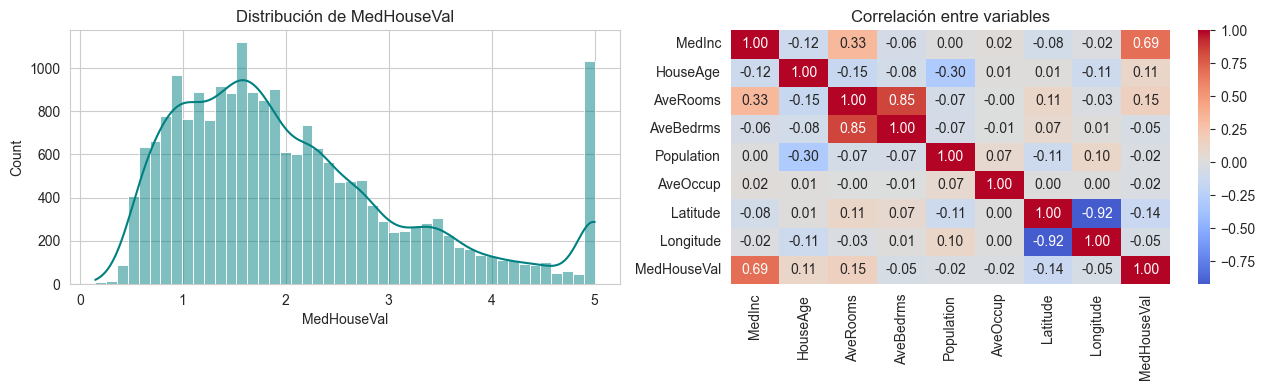

In [4]:
# EDA: variable objetivo y relación con las predictoras
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df_reg["MedHouseVal"], kde=True, ax=axes[0], color="teal")
axes[0].set_title("Distribución de MedHouseVal")

sns.heatmap(df_reg.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f", ax=axes[1])
axes[1].set_title("Correlación entre variables")
plt.tight_layout()
plt.show()

La variable `MedHouseVal`, que representa el valor medio de las viviendas, presenta una **distribución sesgada hacia la derecha** y un pico artificial en el valor **5.0**, asociado al truncamiento aplicado en el dataset. Por otro lado, `MedInc`, que representa el ingreso mediano, es la variable predictora que presenta la **mayor correlación con `MedHouseVal`**. Por esta razón, se espera que tenga una participación importante en la capacidad del modelo para explicar o predecir el valor de las viviendas.

 **Análisis de los resultados**

**Distribución del objetivo.** El histograma muestra que la mayor parte de los distritos se concentra entre **0.5 y 3.0**, con una moda cercana a **1.6**. A medida que aumenta el valor de `MedHouseVal`, la frecuencia de los distritos disminuye gradualmente. Sin embargo, en **5.0** aparece una concentración de **1.000 distritos**, representada por una barra más alta que las barras cercanas. Esto se debe al **tope superior del dataset**: los distritos cuyo valor real de vivienda era igual o superior a este límite quedaron registrados como **5.0**. Por esta razón, para estas observaciones el modelo no conoce el valor exacto de la vivienda, sino que su valor se encuentra en el límite superior o por encima de este. 

**Correlaciones.** La variable `MedInc` presenta la mayor correlación lineal con la variable objetivo, con un **coeficiente de Pearson de `r = 0.69`**, superior al de las demás variables. Le siguen `AveRooms` (**0.15**), `Latitude` (**−0.14**) y `HouseAge` (**0.11**), mientras que el resto presenta correlaciones cercanas a cero. Esto indica que, de manera individual, `MedInc` es la variable que presenta la relación lineal más marcada con `MedHouseVal`, aunque esto no significa que las demás variables no aporten información al modelo.

También se identifican dos pares de variables con una correlación elevada entre sí: `AveRooms`–`AveBedrms` (**0.85**) y `Latitude`–`Longitude` (**−0.92**). La alta correlación entre `AveRooms` y `AveBedrms` indica que ambas variables contienen información parcialmente redundante sobre las características de las viviendas. Por su parte, la fuerte correlación entre `Latitude` y `Longitude` está relacionada con la distribución geográfica de los distritos dentro del estado. Estas correlaciones no impiden utilizar las variables en una SVM, pero muestran que parte de la información proporcionada por algunas variables puede estar relacionada o repetida.

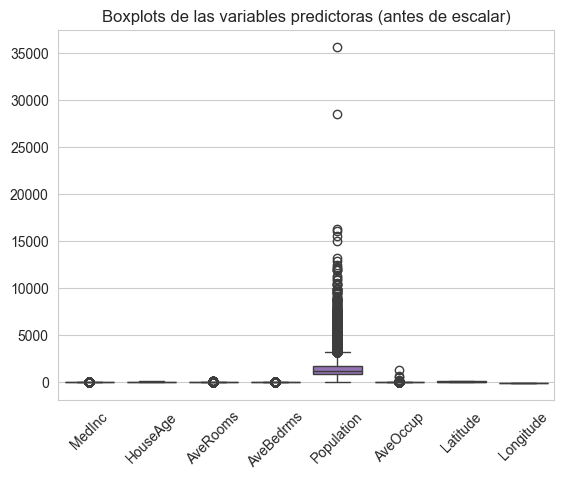

In [5]:
# outliers (SVM con kernel rbf es sensible a la escala, no a outliers directamente, pero sí a puntos muy alejados que se vuelven vectores de soporte "caros")
sns.boxplot(data=df_reg.drop(columns=["MedHouseVal"]))
plt.xticks(rotation=45)
plt.title("Boxplots de las variables predictoras (antes de escalar)")
plt.show()

El kernel RBF no se ve afectado por los valores atípicos de la misma manera que una regresión lineal, ya que no intenta ajustar una única relación lineal a todos los datos. Sin embargo, las observaciones muy alejadas pueden influir en el modelo y convertirse en **vectores de soporte**, aumentando la cantidad de datos que el modelo necesita considerar y, por tanto, su complejidad computacional. Por esta razón, se mantienen todos los registros y se controla la influencia de estas observaciones mediante los parámetros de regularización **`C`** y **`epsilon`**.

**Análisis de los resultados**

El diagrama de cajas está dominado por la variable `Population`, debido a su rango mayor que el de las demás variables. Se observa una gran cantidad de puntos por encima de los bigotes, aproximadamente desde **3.000 hasta 16.000 habitantes**, además de dos valores extremos de alrededor de **28.500 y 35.700**. Estos valores se identifican como observaciones atípicas según el criterio utilizado para construir el diagrama de cajas, aunque esto no significa necesariamente que sean errores en los datos.

Las demás variables aparecen **comprimidas cerca de cero** debido a que todas se representan utilizando el mismo eje que `Population`. Esto dificulta visualizar sus distribuciones individuales y evidencia la **diferencia de escala entre las variables**. Por esta razón, el análisis respalda la decisión de **estandarizar las variables antes de entrenar la SVM**, de manera que aquellas con rangos numéricos más grandes no tengan una influencia desproporcionada sobre el modelo.

## 1.2 División train/test y escalado

In [6]:
X_reg = df_reg.drop(columns=["MedHouseVal"])
y_reg = df_reg["MedHouseVal"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)

El escalado se ajusta **únicamente con el conjunto de entrenamiento** mediante `fit_transform` y posteriormente se aplica al conjunto de prueba utilizando `transform`. De esta manera, se evita utilizar información del conjunto de prueba durante el entrenamiento del modelo y se previene el **data leakage**.

Este paso es importante en SVM con kernel RBF, ya que el cálculo del kernel depende de las **distancias entre las observaciones**. Si una variable tiene un rango mucho mayor que las demás, puede tener una influencia desproporcionada sobre estas distancias y dominar el cálculo del kernel. Por ello, el escalado permite que las variables tengan una influencia más equilibrada en el modelo.

In [7]:
scaler_reg = StandardScaler()
X_train_r_scaled = scaler_reg.fit_transform(X_train_r)
X_test_r_scaled = scaler_reg.transform(X_test_r)

### Submuestra para la búsqueda de hiperparámetros

**Esta celda no estaba incluida en el notebook original.** Las celdas utilizadas para la búsqueda aleatoria de hiperparámetros y la comparación de kernels hacían referencia a `X_train_r_sample` y `y_train_r_sample`, pero estas variables no estaban definidas previamente. Por esta razón, al ejecutar el notebook desde cero se generaba un error `NameError`.

El entrenamiento de un SVR, especialmente con kernels no lineales como RBF, puede volverse costoso a medida que aumenta el número de observaciones. En este caso, realizar la búsqueda de hiperparámetros sobre los **16.512 registros** del conjunto de entrenamiento implicaría entrenar muchos modelos sobre un volumen de datos elevado, aumentando considerablemente el tiempo de ejecución. Por esta razón, la búsqueda se realiza inicialmente sobre una **submuestra aleatoria de 3.000 observaciones**, utilizando los datos **ya escalados**. Esto permite explorar diferentes combinaciones de hiperparámetros de forma más eficiente y mantener la misma escala utilizada luego en `X_test_r_scaled`.

Una vez seleccionada la configuración de hiperparámetros, el **modelo final se reentrena utilizando todo el conjunto de entrenamiento**, de manera que aproveche la totalidad de los datos disponibles antes de realizar la evaluación sobre el conjunto de prueba.

In [8]:
N_SAMPLE = 3000
idx_sample = np.random.RandomState(RANDOM_STATE).choice(
    X_train_r_scaled.shape[0], size=N_SAMPLE, replace=False
)

X_train_r_sample = X_train_r_scaled[idx_sample]
y_train_r_sample = y_train_r.iloc[idx_sample]

print("Train completo :", X_train_r_scaled.shape)
print("Submuestra     :", X_train_r_sample.shape)

Train completo : (16512, 8)
Submuestra     : (3000, 8)


## 1.3 Modelo base (línea de comparación)

In [9]:
# SVR "base", sin ajuste de hiperparámetros (punto de comparación)
svr_base = SVR()  # C=1, gamma='scale', epsilon=0.1 (valores por defecto)
svr_base.fit(X_train_r_scaled, y_train_r)
y_pred_base = svr_base.predict(X_test_r_scaled)

print("SVR base (sin ajustar):")
print(f"  MAE:  {mean_absolute_error(y_test_r, y_pred_base):.4f}")
print(f"  RMSE: {np.sqrt(mean_squared_error(y_test_r, y_pred_base)):.4f}")
print(f"  R²:   {r2_score(y_test_r, y_pred_base):.4f}")

SVR base (sin ajustar):
  MAE:  0.3986
  RMSE: 0.5975
  R²:   0.7276


**Análisis de los resultados**

El SVR base, utilizando `C=1`, `gamma='scale'` y `epsilon=0.1`, obtiene un **MAE de 0.3986**, un **RMSE de 0.5975** y un **R² de 0.7276**. Debido a que `MedHouseVal` está expresada en cientos de miles de dólares, un MAE de 0.3986 equivale a **39.860 USD de error absoluto promedio por distrito**. Por su parte, el **R² de 0.7276** indica que el modelo explica el **72.8% de la variabilidad observada** en el valor de las viviendas del conjunto de prueba.

Estos resultados proporcionan una **línea base** para evaluar el comportamiento del SVR antes de realizar el ajuste de hiperparámetros. A partir de esta referencia se puede determinar si la búsqueda de diferentes valores de `C`, `gamma` y `epsilon` permite mejorar el desempeño del modelo sobre datos que no fueron utilizados durante el entrenamiento.

## 1.4 Ajuste de hiperparámetros (`RandomizedSearchCV`)

- **C**: penalización por error. Alto ⇒ menos sesgo, más varianza.
- **gamma**: alcance del kernel RBF. Alto ⇒ fronteras muy locales (sobreajuste).
- **epsilon**: ancho del tubo donde el error no se penaliza. Alto ⇒ modelo más simple.

La búsqueda aleatoria sobre distribuciones log-uniformes cubre varios órdenes de magnitud con muchas menos combinaciones que una grilla exhaustiva.

In [10]:
# Grilla más amplia, explorada con búsqueda aleatoria (más eficiente que probar todo)
param_dist_svr = {
    "kernel": ["rbf"],
    "C": loguniform(1e-1, 1e3),        # de 0.1 a 1000, en vez de solo [1,10,100]
    "gamma": loguniform(1e-3, 1e0),     # de 0.001 a 1, en vez de solo ["scale", 0.1]
    "epsilon": loguniform(1e-3, 5e-1)   # de 0.001 a 0.5, en vez de solo [0.1, 0.2]
}

random_svr = RandomizedSearchCV(
    SVR(), param_dist_svr, n_iter=40,  # 40 combinaciones al azar
    cv=3, scoring="neg_mean_squared_error",
    n_jobs=-1, verbose=1, random_state=RANDOM_STATE
)
random_svr.fit(X_train_r_sample, y_train_r_sample)

print("Mejores parámetros:", random_svr.best_params_)

svr_model = SVR(**random_svr.best_params_)
svr_model.fit(X_train_r_scaled, y_train_r)

y_pred_r = svr_model.predict(X_test_r_scaled)
print("MAE :", mean_absolute_error(y_test_r, y_pred_r))
print("RMSE:", np.sqrt(mean_squared_error(y_test_r, y_pred_r)))
print("R²  :", r2_score(y_test_r, y_pred_r))

Fitting 3 folds for each of 40 candidates, totalling 120 fits
Mejores parámetros: {'C': np.float64(3.14891164795686), 'epsilon': np.float64(0.36808608148776095), 'gamma': np.float64(0.15702970884055384), 'kernel': 'rbf'}
MAE : 0.3936628484103606
RMSE: 0.5714303222083689
R²  : 0.7508162577018517


**Análisis de los resultados**

La búsqueda aleatoria seleccionó una configuración con **kernel RBF**, `C ≈ 3.15`, `gamma ≈ 0.157` y `epsilon ≈ 0.368`. En comparación con el modelo base, el valor de `C` es aproximadamente **tres veces mayor**, lo que implica una mayor penalización de los errores que quedan fuera del margen establecido. Por otro lado, `gamma` es cercano al valor utilizado por `gamma='scale'` en este conjunto de datos. Al trabajar con **8 variables estandarizadas**, este valor es aproximadamente `1/8 = 0.125`.

El parámetro `epsilon` es aproximadamente **cuatro veces mayor** que el utilizado en el modelo base (`0.1`). Esto significa que el modelo utiliza un **tubo de tolerancia más amplio**, de aproximadamente **±0.37 unidades de `MedHouseVal`**, que corresponde a unos **±37.000 USD**. Las observaciones cuyos errores se encuentran dentro de este intervalo no generan una penalización asociada a la función epsilon-insensitive. Un valor mayor de `epsilon` permite ignorar pequeñas diferencias entre las predicciones y los valores reales, lo que puede contribuir a obtener un modelo menos sensible a variaciones pequeñas o ruido en los datos.

En el conjunto de prueba, el modelo ajustado obtiene un **MAE de 0.3937**, un **RMSE de 0.5714** y un **R² de 0.7508**. Frente al modelo base, el MAE disminuye de **0.3986 a 0.3937**, el RMSE de **0.5975 a 0.5714** y el R² aumenta de **0.7276 a 0.7508**. Por lo tanto, la configuración seleccionada presenta una **mejora en las tres métricas evaluadas** sobre el conjunto de prueba.

## 1.5 Evaluación del modelo ajustado

In [11]:
y_pred_r = svr_model.predict(X_test_r_scaled)

mae = mean_absolute_error(y_test_r, y_pred_r)
mse = mean_squared_error(y_test_r, y_pred_r)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_r, y_pred_r)

print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

MAE:  0.3937
MSE:  0.3265
RMSE: 0.5714
R²:   0.7508


**Interpretación de las métricas**

- **MAE ≈ 0.39** ⇒ el error típico es de unos **39.000 USD** por distrito.
- **RMSE > MAE** ⇒ existen errores grandes puntuales (penaliza el cuadrado), consistente con los distritos truncados en 5.0.
- **R² ≈ 0.75** ⇒ el modelo explica cerca del 75 % de la varianza del valor de la vivienda.

**Análisis de los resultados**

Con el modelo ajustado, **MSE = 0.3265**, **RMSE = 0.5714**, **MAE = 0.3937** y **R² = 0.7508**. El RMSE (≈ 57.100 USD) es 1.45 veces el MAE: como el RMSE penaliza más los errores grandes, esta diferencia indica que existen algunos distritos con errores mayores que el error típico, lo que es coherente con los distritos truncados en 5.0 y con los valores atípicos vistos en el EDA. El R² indica que el modelo deja sin explicar cerca del 25 % de la variabilidad del precio, lo cual es esperable porque el dataset no incluye variables como el estado de la vivienda o el tipo de barrio.

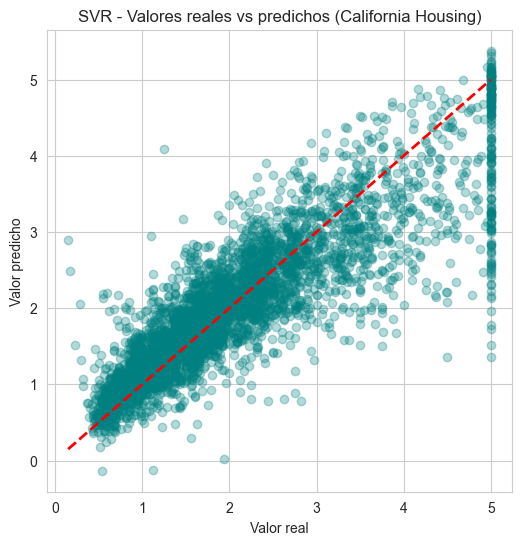

In [12]:
plt.figure(figsize=(6,6))
plt.scatter(y_test_r, y_pred_r, alpha=0.3, color="teal")
plt.plot([y_test_r.min(), y_test_r.max()],
         [y_test_r.min(), y_test_r.max()], "r--", lw=2)
plt.xlabel("Valor real")
plt.ylabel("Valor predicho")
plt.title("SVR - Valores reales vs predichos (California Housing)")
plt.show()

La nube se pega bastante a la diagonal en el rango medio, pero se aplana en la parte alta: el modelo **subestima sistemáticamente** las viviendas caras, justamente por el techo artificial de 5.0 del dataset.

**Análisis de los resultados**

En la gráfica, la mayor densidad de puntos se concentra alrededor de la **diagonal**, para valores reales entre **0.5 y 2.5**, lo que indica que las predicciones se encuentran cerca de los valores observados en el rango donde se concentra la mayoría de los distritos. A partir de valores reales cercanos a **3.0**, la nube de puntos comienza a dispersarse más y una mayor proporción de las predicciones se encuentra por debajo de la diagonal. Esto indica una tendencia del modelo a **subestimar los valores de las viviendas más costosas**.

También se observa una **columna vertical en el valor real 5.0**, con predicciones que van aproximadamente desde **1.4 hasta 5.4**. Esto ocurre porque el valor 5.0 corresponde al límite superior del dataset: diferentes distritos cuyos valores reales pueden ser iguales o superiores a este límite quedan registrados con el mismo valor objetivo. Como consecuencia, el modelo no dispone del valor exacto de estas viviendas y puede generar predicciones inferiores a 5.0. Por lo tanto, el **truncamiento del objetivo limita la capacidad del modelo para representar correctamente los valores más altos**.

Finalmente, se observan algunas predicciones ligeramente negativas, cercanas a **−0.1**. Aunque estos valores no tienen una interpretación económica válida para el precio de una vivienda, pueden aparecer porque el **SVR no impone automáticamente una restricción que limite las predicciones al rango permitido de `MedHouseVal`**. Por esta razón, estas predicciones muestran una limitación del modelo, aunque su magnitud sea pequeña.

## 1.6 Comparación de kernels

Los diferentes modelos se entrenan utilizando **la misma submuestra de datos**, de manera que la comparación entre kernels se realice bajo las mismas condiciones y se reduzca el tiempo de ejecución. Para el kernel polinómico se establecen `degree=2`, `gamma="scale"` y `coef0=1`. Esta configuración se utiliza porque, con los valores por defecto (`degree=3` y `coef0=0`), el modelo presentó un comportamiento inestable y obtuvo un **R² extremadamente negativo**, tal como ocurría en la versión original del notebook. Por esta razón, se ajustaron estos parámetros antes de realizar la comparación con los demás kernels.

In [13]:
# Comparación de kernels para SVR
kernels = ["linear", "poly", "rbf"]
resultados_kernel_r = []

for k in kernels:
    if k == "poly":
        modelo = SVR(kernel="poly", C=10, degree=2, gamma="scale", coef0=1)
    else:
        modelo = SVR(kernel=k, C=10, gamma="scale")

    modelo.fit(X_train_r_sample, y_train_r_sample)
    pred = modelo.predict(X_test_r_scaled)
    resultados_kernel_r.append({
        "Kernel": k,
        "MAE": mean_absolute_error(y_test_r, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test_r, pred)),
        "R2": r2_score(y_test_r, pred),
        "N° vectores de soporte": len(modelo.support_)
    })

df_kernel_r = pd.DataFrame(resultados_kernel_r).round(4)
df_kernel_r

,Kernel,MAE,RMSE,R2,N° vectores de soporte
0,linear,0.5214,0.7861,0.5284,2556
1,poly,0.4591,0.7456,0.5757,2484
2,rbf,0.4142,0.6146,0.7118,2383


El kernel **RBF** presenta el mejor desempeño entre las configuraciones evaluadas. Esto sugiere que la relación entre las variables predictoras y el precio de las viviendas **no se representa adecuadamente mediante una relación lineal simple**. Por otro lado, el kernel polinómico presentó un comportamiento inestable con estos datos, incluso después de ajustar sus parámetros. Por lo tanto, para el desarrollo del modelo se continúa trabajando con el kernel RBF.

**Análisis de los resultados**

Utilizando la misma **submuestra de 3.000 observaciones**, el kernel **RBF** presenta el mejor desempeño entre las tres configuraciones evaluadas, con un **MAE de 0.4142**, un **RMSE de 0.6146** y un **R² de 0.7118**. El kernel polinómico obtiene resultados intermedios, con un **MAE de 0.4591**, un **RMSE de 0.7456** y un **R² de 0.5757**, mientras que el kernel lineal presenta un **MAE de 0.5214**, un **RMSE de 0.7861** y un **R² de 0.5284**.

La diferencia entre el RBF y los otros dos kernels es grande en términos de R²: el RBF supera al polinómico en aproximadamente **0.14 puntos** y al lineal en aproximadamente **0.18 puntos**. Esto sugiere que, dentro de las configuraciones evaluadas, una función no lineal como la que permite el kernel RBF representa mejor la relación entre las variables predictoras y el valor de las viviendas. En cuanto al kernel polinómico, al utilizar `degree=2` y `coef0=1`, deja de presentar el comportamiento inestable observado anteriormente. Sin embargo, su desempeño sigue siendo inferior al del RBF, lo que indica que esta configuración polinómica no captura la estructura de los datos con la misma efectividad.

En cuanto a los **vectores de soporte**, los tres modelos utilizan una proporción elevada de las 3.000 observaciones: **2.556 en el kernel lineal (85%)**, **2.484 en el polinómico (83%)** y **2.383 en el RBF (79%)**. Esto es consistente con el valor de `epsilon = 0.1`, que define un **tubo de tolerancia relativamente estrecho**. Cuando el tubo es pequeño, una mayor cantidad de observaciones queda fuera de la región de tolerancia y pasa a contribuir al ajuste del modelo como vector de soporte. Por esta razón, una proporción elevada de las observaciones termina siendo utilizada como vectores de soporte.

## 1.7 Efecto de la regularización `C`

Este análisis permite observar cómo el parámetro de regularización **`C`** afecta el comportamiento del modelo y el equilibrio entre **sesgo y varianza**. También permite analizar su efecto sobre la complejidad computacional, observando cómo cambia el número de **vectores de soporte** a medida que aumenta `C`. Un valor mayor de `C` penaliza más los errores dentro del margen y puede hacer que el modelo se ajuste con mayor precisión a los datos de entrenamiento, mientras que un valor menor favorece una mayor regularización.

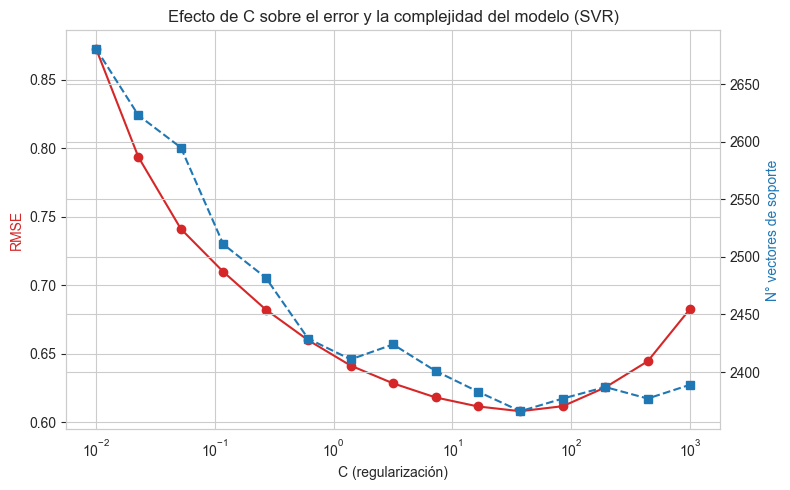

In [14]:
Cs = np.logspace(-2, 3, 15)
errores, n_sv = [], []

for c in Cs:
    m = SVR(kernel="rbf", C=c, gamma="scale")
    m.fit(X_train_r_sample, y_train_r_sample)
    pred = m.predict(X_test_r_scaled)
    errores.append(np.sqrt(mean_squared_error(y_test_r, pred)))
    n_sv.append(len(m.support_))

fig, ax1 = plt.subplots(figsize=(8,5))
ax1.plot(Cs, errores, "o-", color="tab:red", label="RMSE")
ax1.set_xscale("log")
ax1.set_xlabel("C (regularización)")
ax1.set_ylabel("RMSE", color="tab:red")

ax2 = ax1.twinx()
ax2.plot(Cs, n_sv, "s--", color="tab:blue", label="N° vectores de soporte")
ax2.set_ylabel("N° vectores de soporte", color="tab:blue")

plt.title("Efecto de C sobre el error y la complejidad del modelo (SVR)")
fig.tight_layout()
plt.show()

A medida que aumenta `C`, el **RMSE disminuye inicialmente** hasta llegar a una zona en la que comienza a estabilizarse. Al mismo tiempo, el número de **vectores de soporte disminuye**, ya que un valor mayor de `C` permite al modelo ajustarse con mayor precisión a los datos de entrenamiento y hace que menos observaciones queden dentro o fuera del margen de tolerancia.

Sin embargo, después de cierto punto, aumentar `C` deja de producir mejoras importantes en el desempeño sobre el conjunto de prueba. Esto indica que el modelo está aumentando su ajuste al conjunto de entrenamiento sin obtener una mejora equivalente en su capacidad de generalización. Por esta razón, los valores excesivamente altos de `C` pueden asociarse con un **mayor riesgo de sobreajuste**.

**Análisis de los resultados**

**Lo que muestra la gráfica.** El **RMSE** disminuye de forma continua desde aproximadamente **0.87** con `C = 0.01` hasta alcanzar un **mínimo cercano a 0.61** para valores de `C` entre aproximadamente **20 y 80**. A partir de este rango, el error comienza a aumentar nuevamente y llega a aproximadamente **0.68** con `C = 1000`. Esto muestra que, dentro de los valores evaluados, existe una zona intermedia de `C` en la que el modelo obtiene un mejor desempeño sobre el conjunto de prueba. Los valores muy bajos de `C` generan una regularización más fuerte y pueden producir **subajuste**, mientras que el aumento excesivo de `C`, según el comportamiento observado en esta gráfica, puede estar asociado con una pérdida de capacidad de generalización y un posible **sobreajuste**.

En cuanto al número de **vectores de soporte**, este disminuye desde aproximadamente **2.680** hasta unos **2.365** en la zona donde se alcanza el menor RMSE, lo que representa una reducción cercana al **12%**. Después, el número se mantiene estable, alrededor de **2.380–2.390 vectores de soporte**. Por lo tanto, aunque `C` produce algunos cambios en la cantidad de vectores de soporte, la variación es pequeña en relación con las **3.000 observaciones** de la submuestra. En esta prueba, el efecto más evidente de `C` se observa en el **error de predicción**, más que en la complejidad del modelo medida mediante el número de vectores de soporte.

## 1.8 Análisis de residuales

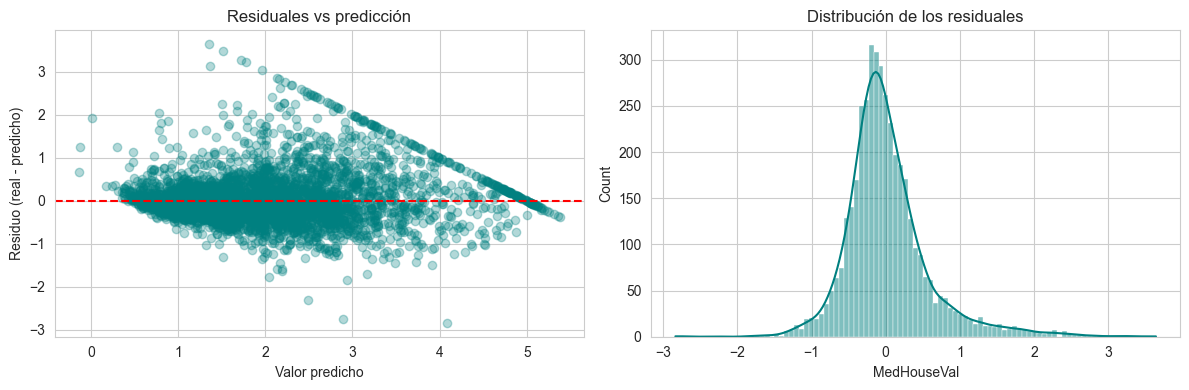

Media de los residuales: 0.0209
Desviación estándar    : 0.5711


In [15]:
residuales = y_test_r - y_pred_r

fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].scatter(y_pred_r, residuales, alpha=0.3, color="teal")
axes[0].axhline(0, color="red", ls="--")
axes[0].set_xlabel("Valor predicho")
axes[0].set_ylabel("Residuo (real - predicho)")
axes[0].set_title("Residuales vs predicción")

sns.histplot(residuales, kde=True, ax=axes[1], color="teal")
axes[1].set_title("Distribución de los residuales")
plt.tight_layout()
plt.show()

print("Media de los residuales:", round(residuales.mean(), 4))
print("Desviación estándar    :", round(residuales.std(), 4))

Los residuales están centrados en ~0 (sin sesgo sistemático global), pero el gráficode residuales vs. predicción muestra una banda diagonal en la parte derecha: son los distritos con valor real truncado en 5.0 que el modelo no puede alcanzar.

**Análisis de los resultados**

Los residuales presentan una **media de 0.0209** (aproximadamente **2.100 USD**) y una **desviación estándar de 0.5711**, prácticamente igual al **RMSE de 0.5714**. Esta cercanía es esperable porque la media de los errores es muy próxima a cero, por lo que el RMSE está determinado por la dispersión de los residuales.

El histograma de los residuales presenta una distribución acampanada, con el centro cercano a **−0.1** y colas más largas hacia la derecha, que alcanzan aproximadamente **+3.6**, que hacia la izquierda, donde llegan hasta aproximadamente **−2.8**. Esta asimetría indica que los errores de mayor magnitud se concentran principalmente en los valores positivos. Dado que el residual se calcula como **valor real − predicción**, un residual positivo corresponde a una **subestimación del modelo**.

En el gráfico de residuales frente a los valores predichos no se observa una estructura sistemática clara en el rango aproximado de **1 a 3**, donde los puntos forman una nube horizontal alrededor de cero. Sin embargo, en la parte superior aparece una recta descendente marcada. Esta corresponde a los distritos cuyo valor real está registrado como **5.0** debido al truncamiento del dataset. Para estas observaciones, el residual se calcula como `5 − predicción`, por lo que disminuye de manera lineal a medida que aumenta la predicción y se aproxima a 5.0.

Finalmente, se observa que la **dispersión de los residuales aumenta a medida que aumentan los valores predichos**, lo que sugiere una **heterocedasticidad leve**. Esto indica que el error del modelo no presenta la misma variabilidad en todo el rango de precios y que las predicciones asociadas con viviendas de mayor valor tienden a presentar una mayor dispersión.

---
# Parte 2 — Clasificación con SVC (Breast Cancer Wisconsin)

El conjunto de datos contiene **569 biopsias**, descritas mediante **30 características morfológicas** relacionadas con el núcleo celular. La variable objetivo corresponde a dos clases: `0 = maligno` y `1 = benigno`.Combina un número relativamente reducido de observaciones con un número considerable de variables predictoras. Además, las características permiten establecer una separación entre las dos clases, aunque el grado de separación dependerá del modelo y de los parámetros utilizados.

## 2.1 Carga y exploración

In [16]:
cancer = load_breast_cancer(as_frame=True)
df_clf = cancer.frame

print(df_clf.shape)
print(df_clf["target"].value_counts())  # 0 = maligno, 1 = benigno
df_clf.head()

(569, 31)
target
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


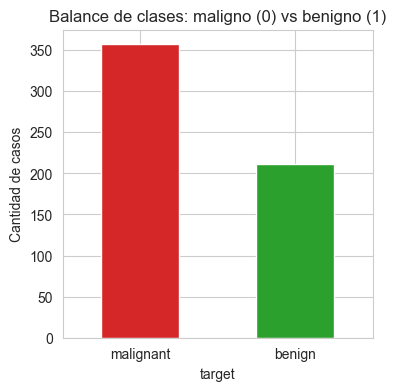

target
1    0.627
0    0.373
Name: proportion, dtype: float64


In [17]:
# EDA: balance de clases (clasificación)
plt.figure(figsize=(4,4))
df_clf["target"].value_counts().plot(kind="bar", color=["#d62728", "#2ca02c"])
plt.xticks([0,1], cancer.target_names, rotation=0)
plt.title("Balance de clases: maligno (0) vs benigno (1)")
plt.ylabel("Cantidad de casos")
plt.show()
print(df_clf["target"].value_counts(normalize=True).round(3))

El desbalance es moderado (63 % / 37 %), así que *accuracy* sigue siendo interpretable, pero se reportan también precision, recall y F1. La división se hace con `stratify=y` para conservar esa proporción en train y test.

**Análisis de los resultados**

El dataset tiene **569 casos**: 357 benignos (62.7 %) y 212 malignos (37.3 %). El desbalance es moderado. En el conjunto de prueba, la división estratificada mantiene esta proporción: 42 casos malignos (36.8 %) y 72 benignos, para un total de 114.

## 2.2 División y escalado

In [18]:
X_clf = df_clf.drop(columns=["target"])
y_clf = df_clf["target"]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf
)

In [19]:
scaler_clf = StandardScaler()
X_train_c_scaled = scaler_clf.fit_transform(X_train_c)
X_test_c_scaled = scaler_clf.transform(X_test_c)

## 2.3 Modelo base

In [20]:
# SVC "base", sin ajuste de hiperparámetros
svc_base = SVC()  # C=1, gamma='scale', kernel='rbf'
svc_base.fit(X_train_c_scaled, y_train_c)
y_pred_base_c = svc_base.predict(X_test_c_scaled)

print("SVC base (sin ajustar):")
print(f"  Accuracy: {accuracy_score(y_test_c, y_pred_base_c):.4f}")
print(f"  F1:       {f1_score(y_test_c, y_pred_base_c):.4f}")

SVC base (sin ajustar):
  Accuracy: 0.9825
  F1:       0.9861


**Análisis de los resultados**

El SVC base (RBF con `C=1`) obtiene **accuracy = 0.9825** (112 de 114 casos correctos) y **F1 = 0.9861**. Este desempeño ya es muy alto sin ajustar nada, lo que muestra que las clases son fáciles de separar una vez estandarizadas las variables.

## 2.4 Ajuste de hiperparámetros (`GridSearchCV`)

Aquí sí conviene una grilla exhaustiva: el dataset es pequeño (455 filas de entrenamiento) y 24 combinaciones × 5 folds se entrenan en segundos. `probability=True` se activa porque más adelante se necesita `predict_proba` para la curva ROC.

In [21]:
param_grid_svc = {
    "kernel": ["rbf", "linear"],
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", 0.01, 0.1]
}

grid_svc = GridSearchCV(
    SVC(probability=True), param_grid_svc, cv=5,
    scoring="accuracy", n_jobs=-1, verbose=1
)
grid_svc.fit(X_train_c_scaled, y_train_c)

print("Mejores parámetros:", grid_svc.best_params_)
svc_model = grid_svc.best_estimator_

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Mejores parámetros: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}


c:\Users\anaso\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


**Análisis de los resultados**

La grilla, compuesta por **24 combinaciones de hiperparámetros evaluadas mediante 5 folds**, realizó un total de **120 ajustes** y seleccionó como mejor configuración el **kernel lineal con `C = 0.1`**. En este caso, `gamma` no tiene efecto sobre el modelo porque este parámetro solo se utiliza en kernels como RBF y no en el kernel lineal.

Se destacan dos aspectos de este resultado. Primero, la configuración seleccionada corresponde a un **modelo más simple que el RBF utilizado por defecto**, lo que indica que, dentro de las combinaciones evaluadas, el kernel lineal obtuvo el mejor desempeño según la métrica utilizada para la búsqueda. Segundo, `C = 0.1` corresponde al **valor más bajo incluido en la grilla**. Esto no significa que un `C` menor vaya a producir un mejor resultado, pero sí indica que sería razonable ampliar la búsqueda hacia valores inferiores para comprobar si una regularización aún mayor puede mantener o mejorar el desempeño del modelo.

## 2.5 Evaluación

In [22]:
y_pred_c = svc_model.predict(X_test_c_scaled)

acc = accuracy_score(y_test_c, y_pred_c)
prec = precision_score(y_test_c, y_pred_c)
rec = recall_score(y_test_c, y_pred_c)
f1 = f1_score(y_test_c, y_pred_c)

print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}")
print("\nReporte completo:\n", classification_report(y_test_c, y_pred_c, target_names=cancer.target_names))

Accuracy:  0.9825
Precision: 0.9861
Recall:    0.9861
F1-score:  0.9861

Reporte completo:
               precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



**Análisis de los resultados**

En el conjunto de prueba, el modelo ajustado obtiene **accuracy = 0.9825**, **precision = 0.9861**, **recall = 0.9861** y **F1 = 0.9861** (tomando *benigno* como clase positiva). El reporte por clase muestra un desempeño equilibrado: la clase maligna alcanza precision y recall de 0.98 (42 casos) y la benigna de 0.99 (72 casos). El promedio macro (0.98) coincide con el ponderado, lo que indica que el pequeño desbalance no afecta el resultado.

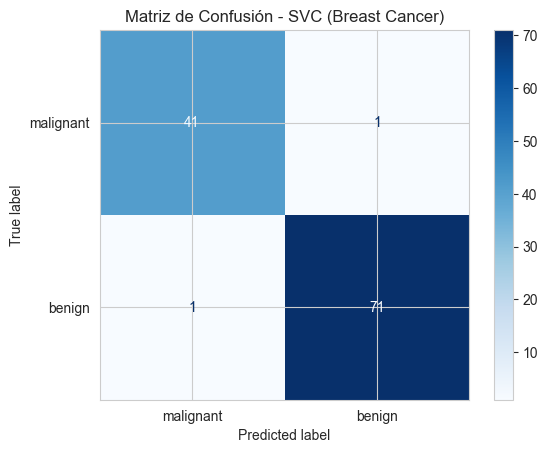

In [23]:
cm = confusion_matrix(y_test_c, y_pred_c)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=cancer.target_names)
disp.plot(cmap="Blues")
plt.title("Matriz de Confusión - SVC (Breast Cancer)")
plt.show()

**Análisis de los resultados**

La matriz de confusión muestra **41 malignos correctamente clasificados, 71 benignos correctamente clasificados, 1 maligno clasificado como benigno (falso negativo) y 1 benigno clasificado como maligno (falso positivo)**. En total son 2 errores de 114. El modelo comete la misma cantidad de errores en ambas clases, sin sesgo hacia ninguna de ellas.

### Métricas desde el punto de vista clínico

En diagnóstico oncológico el error grave es el **falso negativo**: clasificar como benigno un tumor maligno. Por eso se calcula explícitamente el recall de la clase maligna (`pos_label=0`), que las métricas por defecto no muestran.

In [24]:
rec_malignant = recall_score(y_test_c, y_pred_c, pos_label=0)
prec_malignant = precision_score(y_test_c, y_pred_c, pos_label=0)
fn = confusion_matrix(y_test_c, y_pred_c)[0, 1]   # maligno predicho como benigno

print(f"Recall clase MALIGNA   : {rec_malignant:.4f}")
print(f"Precision clase MALIGNA: {prec_malignant:.4f}")
print(f"Falsos negativos (maligno clasificado como benigno): {fn} de {(y_test_c == 0).sum()} casos malignos")

Recall clase MALIGNA   : 0.9762
Precision clase MALIGNA: 0.9762
Falsos negativos (maligno clasificado como benigno): 1 de 42 casos malignos


**Análisis de los resultados**

Para la clase maligna, tanto el **recall como la precision son 0.9762** (41 de 42). Hay **1 falso negativo**: un tumor maligno clasificado como benigno. Es el error de mayor costo clínico, y aunque es solo uno en 42 casos (2.4 %), en una aplicación real el objetivo sería reducirlo a cero, incluso aceptando más falsos positivos (por ejemplo, ajustando el umbral de decisión).

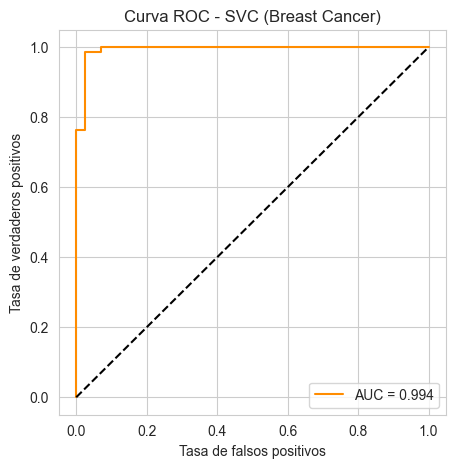

In [25]:
y_proba_c = svc_model.predict_proba(X_test_c_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test_c, y_proba_c)
auc = roc_auc_score(y_test_c, y_proba_c)

plt.figure(figsize=(5,5))
plt.plot(fpr, tpr, color="darkorange", label=f"AUC = {auc:.3f}")
plt.plot([0,1],[0,1], "k--")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC - SVC (Breast Cancer)")
plt.legend()
plt.show()

Un AUC cercano a 1 indica que el modelo ordena casi perfectamente los casos: existe un umbral que separa ambas clases con muy pocos errores.

**Análisis de los resultados**

El **AUC es 0.994**. La curva sube casi verticalmente: con 0 falsos positivos ya se detecta ≈ 76 % de los casos benignos, con una tasa de falsos positivos de ≈ 3 % se alcanza ≈ 98 %, y con ≈ 7 % se llega al 100 %. Una AUC tan cercana a 1 indica que el modelo **ordena** casi perfectamente los casos, y que existen umbrales que separan las clases con muy pocos errores; el desempeño no depende de un umbral muy específico.

## 2.6 Frontera de decisión (proyección con PCA)

Las 30 variables se proyectan a 2 componentes principales solo **para visualizar**.

> **Corrección:** el código original fijaba `kernel="rbf"` aunque la búsqueda había elegido `linear`, así que el dibujo no correspondía al modelo seleccionado. Ahora se reutilizan los parámetros ganadores con `**grid_svc.best_params_`.

Varianza explicada por las 2 componentes: [0.444 0.189] | total: 0.634


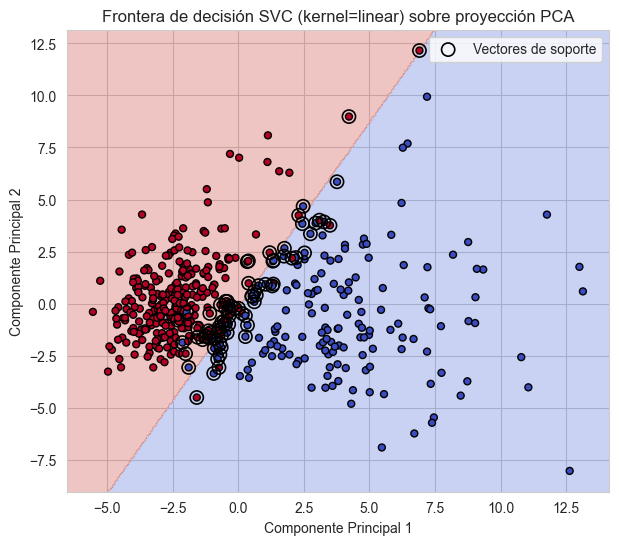

In [26]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_c_scaled)
print("Varianza explicada por las 2 componentes:",
      pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

# mismo kernel e hiperparámetros que el modelo ganador
svc_2d = SVC(**grid_svc.best_params_)
svc_2d.fit(X_train_pca, y_train_c)

xx, yy = np.meshgrid(
    np.linspace(X_train_pca[:,0].min()-1, X_train_pca[:,0].max()+1, 300),
    np.linspace(X_train_pca[:,1].min()-1, X_train_pca[:,1].max()+1, 300)
)
Z = svc_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(7,6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
plt.scatter(X_train_pca[:,0], X_train_pca[:,1], c=y_train_c, cmap="coolwarm",
            edgecolors="k", s=25)
plt.scatter(X_train_pca[svc_2d.support_, 0], X_train_pca[svc_2d.support_, 1],
            s=90, facecolors="none", edgecolors="k", linewidths=1.2,
            label="Vectores de soporte")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.title(f"Frontera de decisión SVC (kernel={svc_2d.kernel}) sobre proyección PCA")
plt.legend()
plt.show()

Los puntos circulados son los **vectores de soporte**: las únicas observaciones que definen la frontera. Ese es el rasgo distintivo de las SVM frente a otros modelos.

**Análisis de los resultados**

Las dos primeras componentes principales explican solo **63.4 %** de la varianza (44.4 % + 18.9 %), por lo que esta gráfica es una representación parcial de los datos. Aun así se ve una separación clara: los casos benignos (rojo, mayoría) se agrupan hacia la izquierda y los malignos (azul) hacia la derecha, y la frontera lineal las divide con solapamiento moderado solo en la zona central. Los vectores de soporte (círculos) se concentran a lo largo de la frontera, y también aparecen algunos puntos aislados de una clase dentro de la región de la otra (por ejemplo, arriba a la derecha): son observaciones que violan el margen y participan en la definición del modelo. Recordemos que este SVC se entrena solo con 2 componentes, por lo que ilustra la idea de la frontera pero no es el mismo modelo de 30 variables usado en la evaluación.

## 2.7 Comparación de kernels

In [27]:
# Comparación de kernels para SVC
resultados_kernel_c = []

for k in kernels:
    modelo = SVC(kernel=k, C=10, gamma="scale")
    modelo.fit(X_train_c_scaled, y_train_c)
    pred = modelo.predict(X_test_c_scaled)
    resultados_kernel_c.append({
        "Kernel": k,
        "Accuracy": accuracy_score(y_test_c, pred),
        "F1": f1_score(y_test_c, pred),
        "N° vectores de soporte": modelo.support_.shape[0]
    })

df_kernel_c = pd.DataFrame(resultados_kernel_c).round(4)
df_kernel_c

,Kernel,Accuracy,F1,N° vectores de soporte
0,linear,0.9825,0.9861,26
1,poly,0.9737,0.9796,99
2,rbf,0.9737,0.9790,84


El kernel **lineal** obtiene el mejor resultado con **muchos menos vectores de soporte**: tras estandarizar, las clases son casi linealmente separables en 30 dimensiones y un kernel más flexible solo añade complejidad sin ganancia.

**Análisis de los resultados**

El kernel **lineal** obtiene el mejor resultado (**accuracy 0.9825, F1 0.9861**) frente al polinómico (0.9737 / 0.9796) y al RBF (0.9737 / 0.9790). La diferencia de accuracy equivale a **un solo caso** de los 114 del test (0.0088), por lo que no es una diferencia concluyente: en la práctica los tres kernels rinden igual. Lo que sí cambia es la complejidad: el lineal necesita solo **26 vectores de soporte (≈ 6 % de los 455 de entrenamiento)**, mientras que el RBF usa 84 (≈ 18 %) y el polinómico 99 (≈ 22 %). Ante un rendimiento equivalente, el modelo más simple es preferible.

### Variables más influyentes (solo válido con kernel lineal)

Con `kernel="linear"` los coeficientes sí son interpretables: indican cuánto empuja cada variable hacia la clase benigna (positivo) o maligna (negativo).

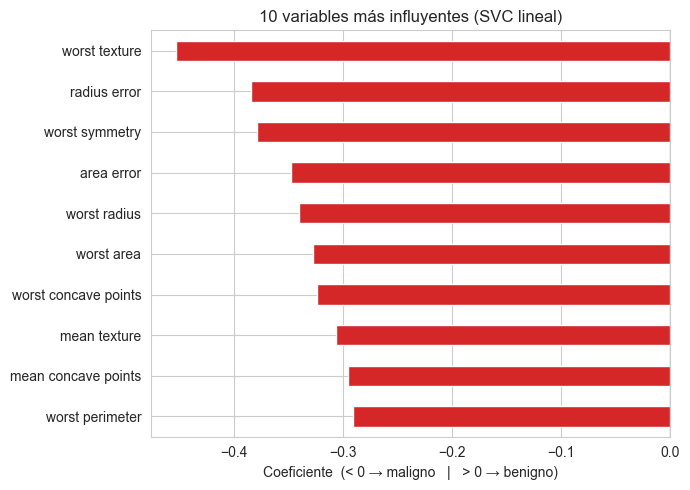

In [28]:
if svc_model.kernel == "linear":
    coefs = pd.Series(svc_model.coef_[0], index=X_clf.columns)
    top = coefs.reindex(coefs.abs().sort_values(ascending=False).index)[:10][::-1]

    plt.figure(figsize=(7,5))
    top.plot(kind="barh", color=["#d62728" if v < 0 else "#2ca02c" for v in top])
    plt.axvline(0, color="k", lw=0.8)
    plt.title("10 variables más influyentes (SVC lineal)")
    plt.xlabel("Coeficiente  (< 0 → maligno   |   > 0 → benigno)")
    plt.tight_layout()
    plt.show()
else:
    print(f"El modelo final usa kernel '{svc_model.kernel}': los coeficientes no son interpretables directamente.")

**Análisis de los resultados**

Las 10 variables con mayor **coeficiente absoluto** presentan todas un **signo negativo**, lo que significa que, manteniendo la codificación utilizada en el modelo (`0 = maligno`, `1 = benigno`), valores altos de estas variables tienden a desplazar la predicción hacia la **clase maligna**. Las variables con mayor peso absoluto son `worst texture` (≈ −0.45), `radius error` (≈ −0.38), `worst symmetry` (≈ −0.38), `area error` (≈ −0.35) y `worst radius` (≈ −0.34). Les siguen `worst area`, `worst concave points`, `mean texture`, `mean concave points` y `worst perimeter`, con coeficientes entre aproximadamente **−0.29 y −0.33**.

---
# Parte 3 — Comparación global y conclusiones

## 3.1 Desempeño por kernel en ambas tareas

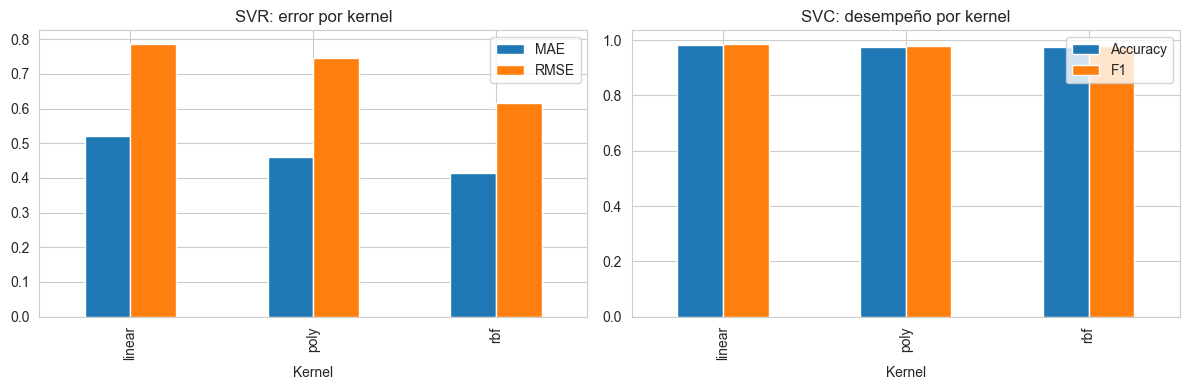

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
df_kernel_r.set_index("Kernel")[["MAE","RMSE"]].plot(kind="bar", ax=axes[0], title="SVR: error por kernel")
df_kernel_c.set_index("Kernel")[["Accuracy","F1"]].plot(kind="bar", ax=axes[1], title="SVC: desempeño por kernel", color=["#1f77b4","#ff7f0e"])
plt.tight_layout()
plt.show()

**Análisis de los resultados**

**SVR (izquierda):** el error disminuye de forma clara del kernel lineal al RBF: el RMSE pasa de ≈ 0.79 (lineal) a ≈ 0.75 (polinómico) y ≈ 0.61 (RBF), y el MAE de ≈ 0.52 a ≈ 0.46 y ≈ 0.41. El RBF reduce el RMSE cerca de un 22 % frente al lineal. **SVC (derecha):** las barras de accuracy y F1 son prácticamente iguales en los tres kernels (≈ 0.97–0.99). En resumen, la elección del kernel importa mucho en la regresión, donde la relación es no lineal, y casi nada en la clasificación, donde los datos ya son casi separables.

## 3.2 ¿Valió la pena ajustar los hiperparámetros?

> **Corrección:** la tabla decía "GridSearchCV" para el SVR, pero ese modelo se ajustó con `RandomizedSearchCV`.

In [30]:
# Tabla resumen final: ¿valió la pena ajustar hiperparámetros?
resumen_svr = pd.DataFrame({
    "Modelo": ["SVR base (sin ajustar)", "SVR ajustado (RandomizedSearchCV)"],
    "MAE": [mean_absolute_error(y_test_r, y_pred_base), mean_absolute_error(y_test_r, y_pred_r)],
    "RMSE": [np.sqrt(mean_squared_error(y_test_r, y_pred_base)), np.sqrt(mean_squared_error(y_test_r, y_pred_r))],
    "R2": [r2_score(y_test_r, y_pred_base), r2_score(y_test_r, y_pred_r)]
}).round(4)
resumen_svr

,Modelo,MAE,RMSE,R2
0,SVR base (sin ajustar),0.3986,0.5975,0.7276
1,SVR ajustado (RandomizedSearchCV),0.3937,0.5714,0.7508


In [31]:
resumen_svc = pd.DataFrame({
    "Modelo": ["SVC base (sin ajustar)", "SVC ajustado (GridSearchCV)"],
    "Accuracy": [accuracy_score(y_test_c, y_pred_base_c), accuracy_score(y_test_c, y_pred_c)],
    "F1": [f1_score(y_test_c, y_pred_base_c), f1_score(y_test_c, y_pred_c)]
}).round(4)
resumen_svc

,Modelo,Accuracy,F1
0,SVC base (sin ajustar),0.9825,0.9861
1,SVC ajustado (GridSearchCV),0.9825,0.9861


En **regresión**, el ajuste de hiperparámetros genera una mejora en el desempeño del modelo: el **RMSE disminuye de 0.597 a 0.571**, mientras que el **R² aumenta de 0.728 a 0.751**. Esto indica que la configuración ajustada logra un mejor desempeño sobre los datos de prueba.

En **clasificación**, el modelo con los parámetros por defecto ya obtiene un desempeño muy alto en el conjunto de datos, por lo que el ajuste de hiperparámetros **no produce una mejora en la accuracy**. Sin embargo, la configuración seleccionada utiliza un **kernel lineal con `C=0.1`**, en lugar del kernel RBF utilizado por defecto. Al tratarse de un modelo más sencillo, esta configuración reduce la complejidad del modelo y puede disminuir el riesgo de sobreajuste, manteniendo el mismo nivel de accuracy observado.

**Análisis de los resultados**

**Regresión:** con el ajuste el MAE baja 0.005 (−1.2 %), el RMSE baja 0.026 (−4.4 %, de 0.5975 a 0.5714) y el R² sube 0.023 (de 0.7276 a 0.7508). Es una mejora pequeña pero consistente en todas las métricas. **Clasificación:** los resultados del modelo base y del ajustado son idénticos (accuracy 0.9825, F1 0.9861), porque ambos cometen los mismos 2 errores en el test; el ajuste solo cambia el tipo de modelo (lineal con `C=0.1` en lugar de RBF).

## 3.3 Chequeo de sobreajuste (train vs. test)

In [32]:
# Chequeo de sobreajuste: comparar train vs test
train_pred_r = svr_model.predict(X_train_r_scaled)
train_pred_c = svc_model.predict(X_train_c_scaled)

print("SVR — R² train:", round(r2_score(y_train_r, train_pred_r), 4),
      "| R² test:", round(r2_score(y_test_r, y_pred_r), 4))
print("SVC — Accuracy train:", round(accuracy_score(y_train_c, train_pred_c), 4),
      "| Accuracy test:", round(accuracy_score(y_test_c, y_pred_c), 4))

SVR — R² train: 0.7753 | R² test: 0.7508
SVC — Accuracy train: 0.9846 | Accuracy test: 0.9825


**Análisis de los resultados**

**SVR:** el modelo obtiene un **R² de 0.7753 en train y 0.7508 en test**, con una diferencia de aproximadamente **0.025 puntos**. La brecha pequeña entre ambos resultados indica que el desempeño del modelo se mantiene similar al pasar de los datos de entrenamiento a los datos de prueba, lo que sugiere una **buena capacidad de generalización** y no evidencia un sobreajuste importante.

**SVC:** el modelo alcanza una **accuracy de 0.9846 en train**, equivalente a **7 errores de 455 observaciones**, y una accuracy de **0.9825 en test**, con una diferencia de aproximadamente **0.002 puntos**. Al igual que en el SVR, la diferencia entre el desempeño en entrenamiento y prueba es muy pequeña, lo que indica que el modelo mantiene un comportamiento consistente sobre datos no utilizados durante el entrenamiento.

### Validación cruzada del modelo final

Una sola partición train/test puede dar una estimación optimista o pesimista por azar. La validación cruzada entrega el desempeño **medio ± desviación**, una medida más honesta.

In [33]:
cv_svc = cross_val_score(svc_model, X_train_c_scaled, y_train_c, cv=5, scoring="accuracy")
print(f"SVC — Accuracy CV (5 folds): {cv_svc.mean():.4f} ± {cv_svc.std():.4f}")

# Para SVR se usa la submuestra: la validación cruzada sobre 16.512 filas es muy costosa
cv_svr = cross_val_score(svr_model, X_train_r_sample, y_train_r_sample, cv=3, scoring="r2")
print(f"SVR — R² CV (3 folds, submuestra de {N_SAMPLE}): {cv_svr.mean():.4f} ± {cv_svr.std():.4f}")

SVC — Accuracy CV (5 folds): 0.9802 ± 0.0162


c:\Users\anaso\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\anaso\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\anaso\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\anaso\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\

SVR — R² CV (3 folds, submuestra de 3000): 0.7156 ± 0.0151


**Análisis de los resultados**

**SVC:** la accuracy obtenida mediante validación cruzada es de **0.9802 ± 0.0162**, cercana a la accuracy obtenida en el conjunto de prueba (**0.9825**). Indica que el desempeño del modelo se mantiene similar en diferentes particiones de los datos y que el resultado no depende de una única división entre entrenamiento y prueba. La desviación estándar de aproximadamente **0.016**, equivalente a 1.6 puntos porcentuales, indica que la accuracy presenta cierta variación entre los folds, pudiendo encontrarse aproximadamente entre **96% y 100%**. Esta variabilidad es razonable considerando el tamaño pequeño del conjunto de datos.

**SVR:** el R² obtenido mediante validación cruzada es de **0.7156 ± 0.0151**, calculado utilizando **3 folds sobre una submuestra de 3.000 observaciones**. Este valor es inferior al **R² de 0.7508** obtenido sobre el conjunto de prueba. Sin embargo, ambos resultados no son comparables, ya que en cada fold de la validación cruzada el modelo se entrena utilizando aproximadamente **2.000 observaciones**, mientras que el modelo evaluado sobre test fue entrenado con un conjunto de entrenamiento mayor. La desviación estándar de **0.0151** es baja, lo que indica que el desempeño del modelo se mantiene estable entre los diferentes folds.

Finalmente, debe tenerse en cuenta que los hiperparámetros del SVR fueron seleccionados utilizando estos mismos datos de la submuestra. Por esta razón, la estimación obtenida mediante esta validación cruzada puede ser **ligeramente optimista**, ya que los datos utilizados para evaluar el modelo también participaron en el proceso de selección de la configuración.

## 3.4 Conclusiones

**Sobre el desempeño**

1. **SVR (California Housing):** el modelo obtiene un **R² ≈ 0.75** y un **MAE ≈ 0.39**, equivalente a un error absoluto promedio de aproximadamente **39.000 USD**. Los errores tienden a ser mayores en los distritos con valores de vivienda más altos, en parte debido al **truncamiento de `MedHouseVal` en 5.0**, que impide conocer el valor exacto de las viviendas que alcanzan o superan este límite. La diferencia entre el desempeño en train y test es pequeña (**R² ≈ 0.78 frente a ≈ 0.75**), por lo que no se observa evidencia de un sobreajuste importante.

2. **SVC (Breast Cancer):** el modelo alcanza una **accuracy ≈ 0.98** y un **AUC ≈ 0.99**. Además, presenta un número reducido de falsos negativos. En este conjunto de datos, este tipo de error es relevante porque corresponde a observaciones de la clase maligna que el modelo clasifica incorrectamente como benignas. Por esta razón, además de la accuracy y el AUC, resulta importante analizar métricas como el **recall de la clase maligna**.

**Sobre las SVM como método**

3. **El escalado es fundamental.** Los modelos SVM son sensibles a la escala de las variables y esta importancia es clara al utilizar el **kernel RBF**, cuyo cálculo depende de las distancias entre las observaciones. Sin estandarización, variables con rangos numéricos muy grandes, como `Population` en California Housing, podrían tener una influencia desproporcionada en estas distancias. Por ello, el escalado debe realizarse utilizando únicamente los datos de entrenamiento para evitar *data leakage*.

4. **No existe un kernel que sea universalmente mejor.** En las configuraciones evaluadas, el **RBF obtuvo mejores resultados en la regresión**, lo que indica que permitió representar mejor la relación no lineal entre las variables predictoras y el valor de las viviendas. En clasificación, el **kernel lineal obtuvo el mejor resultado entre las configuraciones evaluadas**, manteniendo una accuracy muy alta. Esto muestra que la elección del kernel depende de la estructura del conjunto de datos y de la configuración utilizada. El kernel polinómico presentó un desempeño inferior o menos estable en las pruebas realizadas.

5. **Una mayor complejidad no implica necesariamente un mejor modelo.** En la clasificación, el kernel lineal seleccionado utiliza **26 vectores de soporte**, frente a **84 del RBF**. Esto representa una estructura más sencilla en el número de observaciones que participan como vectores de soporte y, además, facilita la interpretación de los coeficientes del modelo lineal. Sin embargo, el número de vectores de soporte por sí solo no determina toda la complejidad ni el costo computacional de un modelo.

6. **El costo computacional es una consideración importante en SVR.** Los modelos SVM con kernels no lineales pueden presentar un costo computacional elevado a medida que aumenta el número de observaciones. Por esta razón, la búsqueda de hiperparámetros del SVR se realizó inicialmente sobre una **submuestra de 3.000 registros**, lo que permitió reducir el tiempo necesario para evaluar las diferentes configuraciones. Una vez seleccionados los hiperparámetros, el modelo final se **reentrenó utilizando todo el conjunto de entrenamiento** para aprovechar la información disponible.

### **Limitaciones y posibles mejoras**

- Una posible mejora para el SVR consiste en analizar el tratamiento de los valores de `MedHouseVal` que se encuentran en el límite superior de **5.0**. Debido al truncamiento del objetivo, el modelo no puede conocer el valor exacto de los distritos que alcanzan o superan este límite. Por esta razón, podría evaluarse el efecto de realizar transformaciones de la variable objetivo o utilizar métodos que consideren la existencia de este límite, en lugar de asumir que todos los valores registrados como 5.0 representan exactamente el mismo valor.

- También sería posible probar alternativas más escalables para el conjunto de datos de California Housing, como **`LinearSVR`** o **`SGDRegressor`**, especialmente si se busca reducir el costo computacional al trabajar con un mayor número de observaciones.

- En el caso de clasificación, una posible mejora consiste en **ajustar el umbral de decisión** del SVC de acuerdo con el objetivo del análisis. Si se busca reducir los falsos negativos de la clase maligna, se podría utilizar un umbral que favorezca un mayor *recall*, aunque esto podría producir un aumento de los falsos positivos y una disminución de la precisión. Por lo tanto, la selección del umbral debe realizarse considerando el costo relativo de ambos tipos de error.


## Cuándo usar SVM y cuándo no

### Cuándo una SVM es buena opción

- **Pocas observaciones y muchas variables.** Es el caso clásico y es exactamente el de Breast Cancer: 455 filas de entrenamiento y 30 variables, con accuracy de 0.98. El margen máximo actúa como regularizador natural y evita sobreajustar incluso cuando hay más variables que datos, situación típica en genómica, análisis de texto o imágenes médicas.
- **La frontera entre clases no es una recta.** El truco del kernel permite construir fronteras curvas sin crear explícitamente el espacio de mayor dimensión. En la regresión se vio con claridad: el kernel RBF pasó de un R² de 0.53 (lineal) a 0.71.
- **Datos limpios, numéricos y estandarizados.** La SVM no supone ninguna distribución de los datos, pero sí exige que las variables estén en escalas comparables.
- **Cuando importa más acertar que explicar.** Si el objetivo es puramente predictivo, la falta de interpretabilidad del kernel RBF deja de ser un problema.

### Cuándo conviene otra cosa

- **Datasets grandes.** El entrenamiento crece entre $O(n^2)$ y $O(n^3)$. Por eso en este trabajo hubo que reducir a 3.000 filas solo para poder buscar hiperparámetros: con 16.512 la búsqueda era inviable. Por encima de unas 50.000–100.000 filas, `LinearSVC`, `LinearSVR`, `SGDClassifier` o un modelo de árboles (Random Forest, XGBoost, LightGBM) resultan mucho más prácticos.
- **Cuando se necesitan probabilidades.** La SVM no las entrega de forma nativa: devuelve una distancia al hiperplano. Con `probability=True` se calibran mediante *Platt scaling*, lo que implica una validación cruzada interna adicional y más tiempo de cómputo. Si el problema exige probabilidades bien calibradas, una regresión logística o un modelo de *gradient boosting* son mejor punto de partida.
- **Cuando hay que explicar cada predicción.** Solo con `kernel="linear"` los coeficientes son interpretables, como se hizo en la sección 2.7. Con RBF el modelo es una caja negra y habría que recurrir a métodos como SHAP.
- **Con muchas variables categóricas o datos mixtos.** El *one-hot encoding* genera espacios dispersos donde las distancias pierden sentido. Los modelos basados en árboles manejan este tipo de datos de forma nativa.
- **Con mucho ruido o clases muy solapadas.** Las observaciones ruidosas terminan convirtiéndose en vectores de soporte, lo que encarece el modelo sin mejorarlo.
- **Cuando hay poco tiempo para ajustar.** La SVM es muy sensible a `C`, `gamma` y `epsilon`: sin búsqueda de hiperparámetros el desempeño puede ser pobre. Un Random Forest con valores por defecto suele dar resultados aceptables de entrada.
- **Multiclase con muchas clases.** `SVC` lo resuelve internamente con la estrategia *one-vs-one*, lo que implica entrenar $k(k-1)/2$ modelos distintos.

### Limitaciones concretas observadas en este trabajo

1. **Costo computacional (SVR).** Obligó a trabajar con una submuestra de 3.000 de los 16.512 registros de entrenamiento para poder realizar la búsqueda de hiperparámetros. Es la limitación más tangible que encontramos.
2. **Sensibilidad a la escala.** Sin estandarizar, `Population` (con valores de hasta 35.682) habría dominado por completo el cálculo del kernel frente a `AveBedrms`, que ronda 1.
3. **Falta de interpretabilidad del RBF.** En la regresión, el mejor modelo no permite cuantificar el aporte de cada variable. En la clasificación tuvimos suerte: ganó el kernel lineal y sí pudimos leer los coeficientes.
4. **El modelo no conoce los límites del problema.** El SVR produjo algunas predicciones ligeramente negativas (≈ −0.1), imposibles para un precio de vivienda, porque nada en la formulación restringe la salida al rango válido.
5. **Las limitaciones de los datos no las arregla el modelo.** El techo artificial de 5.0 en `MedHouseVal` explica buena parte del error en los distritos más costosos, y ningún kernel puede recuperar información que no está en los datos.

### Regla práctica

Si se tienen **menos de unas 10.000 filas**, variables numéricas ya escaladas y se sospecha una frontera no lineal, la SVM es una excelente primera opción. Si se trabaja con cientos de miles de filas, datos mixtos, o se necesita interpretabilidad o probabilidades calibradas, conviene empezar por otro método y usar la SVM como modelo de comparación.